# Initalize libraries

## Import libraries

In [1]:
import sys, os
import time
from os.path import join
from os import path
from importlib import reload
from getpass import getuser
from tqdm.auto import tqdm
import scipy

import skimage
#data
import xarray as xr
import h5py

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm

# pyFAI
import pyFAI
from pyFAI.azimuthalIntegrator import AzimuthalIntegrator
from pyFAI.detectors import Detector

# Self-written libraries
sys.path.append(join(os.getcwd(), "library"))
import helper_functions as helper
import interactive
from interactive import cimshow
import mask_lib

# Gifs
import imageio


from scipy.ndimage import map_coordinates

plt.rcParams["figure.constrained_layout.use"] = True  # replaces plt.tight_layout

  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 198, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 88, in _run_code
    exec(code, run_globals)
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 758, in start
    self.io_loop.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 211, in start
    self.asyncio_loop.run_forever()
  File "/asap3/petra3

In [2]:
# Is there a GPU?
try:
    # Cupy
    import cupy as cp
    import cupyx as cpx

    GPU = True

    print("GPU available")

    # Self-written library
    import CCI_core_cupy as cci
except:
    GPU = False
    import CCI_core as cci

    print("GPU unavailable")

parula_map = cci.parula_map()

GPU unavailable


In [3]:
# interactive plotting
import ipywidgets

%matplotlib widget

# Auto formatting of cells
#%load_ext jupyter_black

## Experiment specific Functions

In [4]:
facility = "PETRA" # Options: "SwissFEL", "MAXI"
BEAMTIMEID = 11022228 # Proposal number
data_fname_prefix = "2602_orbitronics"
USER = getuser()

# Number or jobs for analysis
NR_JOBS = 32

# Facility specific loading functions
if facility == "PETRA":
    import PETRA_MaxP04_loading as loading
elif facility == "MAXI":
    import MAXI_loading as loading
elif facility == "SwissFEL":
    from sfdata import SFDataFiles, SFScanInfo, SFProcFile
    import Swiss_FEL_Loading as loading

BASEFOLDER = "/asap3/petra3/gpfs/p04/2026/data/%s/" % BEAMTIMEID
DATAFOLDER = join(BASEFOLDER,"raw")

reload(loading)
# Load dictionary for keys etc
mnemonics = loading.load_mnemonics()

### Loading

In [5]:
def line_scan(image, x1, y1, x2, y2, num=None):
    # Length of the line
    length = int(np.hypot(x2 - x1, y2 - y1))
    
    if num is None:
        num = length

    # Generate line coordinates
    x = np.linspace(x1, x2, num)
    y = np.linspace(y1, y2, num)

    # Extract values with interpolation
    coords = np.vstack((y, x))  # note: (row, col) = (y, x)
    values = map_coordinates(image, coords, order=1)

    return values





In [6]:
def generate_filename(scan_nr: int):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """
    return join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}.nxs")

def get_marana_filenames(scan_nr: int, file_indices = None):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """

    scan_count = load_key(scan_nr, "/scan/data/point_nb")
    if np.ndim(scan_count) == 0:
        scan_count = 1
    elif np.ndim(scan_count) > 0:
        scan_count = scan_count.shape[0]

    #this does not work anymore since we are sampling with 200 frames per file -> os.listdir....
    
    names = os.listdir(join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}","marana"))
    names = [name for name in names if name[-2:]=="nx"]
    fnames = np.array([join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}","marana",name) for name in names])
    fnames = np.array(sorted(fnames))
    files = []
    for file in fnames:
        with h5py.File(file, "r") as f:
            if len(f["/entry/instrument/detector/timestamps"][()]) > 3:
                files.append(file)
    fnames = np.array(files)
    if file_indices is not None:
        fnames = fnames[file_indices]
    
        if type(fnames) == str:
            fnames = np.array([fnames])

    
    return fnames

def load_data(scan_id, keypath=mnemonics["collection"], keys=None):
    """
    Load data of all specified keys from keypath

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    keypath : str
        path of nexus file tree to relevant data field
    keys : str or list of strings
        keys to load from keypath

    Output
    ======
    data : dict
        data dictionary of keys
    ======
    author: ck 2024
    """

    # Generate filename from scan_id
    fname = generate_filename(scan_id)

    # load data with basic loading function
    data = loading.load_data(fname, keypath, keys=keys)

    return data


def load_key(scan_id, key):
    """
    Load any kind of data specified by key (path)

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    key : str
        key path of nexus file tree to relevant data field

    Output
    ======
    data : dict
        data dictionaray on single key
    ======
    author: ck 2024
    """
    # Generate filename from scan_id
    fname = generate_filename(scan_id)
    # load data with basic loading function
    data = loading.load_key(fname, key)

    return data
    
def load_images(im_id, file_indices = None):
    """
    Loads images for a given scan id

    Parameter
    =========
    im_id : int
        experimental identifier of image scan

    Output
    ======
    images : array
        stack of all images the correspond to the id
    ======
    author: ck 2024
    """

    # Generate filesnames
    fnames  = get_marana_filenames(im_id, file_indices = file_indices)

    # load data
    images = [loading.load_key(fname,mnemonics["nx_marana"]) for fname in tqdm(fnames)]
    images = np.stack(images)
    
    return images.astype("float32")

# Full image loading procedure
def load_processing(im_id, file_indices = None, binning = 1, crop = None):
    """
    Loads images, averaging of two individual images (scans in tango consist of two images),
    padding to square shape, Additional cropping (optional)
    """

    # Load data
    images = load_images(im_id, file_indices = file_indices)

    # Optional cropping
    if crop is not None:
        images = images[..., :crop, :crop]

    # Binning
    if binning > 1:
        images = helper.binning(images, binning)

    # Average over all images
    if images.ndim == 4:
        image = np.mean(images, axis=(0, 1))
    elif images.ndim == 3:
        image = np.mean(images, axis=(0))
    elif images.ndim == 2:
        image = images.copy()
    images = np.stack(images)
    
    return image, images

In [7]:
# Full image loading procedure
def load_processing_singlephoton(im_id, file_indices = None, binning = 1, crop = None, sigma=(0,0,0),thr=2):
    """
    Loads images, averaging of two individual images (scans in tango consist of two images),
    padding to square shape, Additional cropping (optional)
    """

    # Load data
    images = load_images(im_id, file_indices = file_indices)

    # Optional cropping
    if crop is not None:
        images = images[..., :crop, :crop]

    # Binning
    if binning > 1:
        images = helper.binning(images, binning)

    #temp=images[0].copy()
    
    if thr>0:
        offset=np.average(images[...,-100:,:100])
        images=images-offset
        if sigma[1]>0:
            temp=scipy.ndimage.gaussian_filter(images, sigma=sigma)
        else:
            temp=images.copy()
            
        images[temp<thr]=0
    else:
        temp=0
    temp=images[0].copy()
    

    # Average over all images
    if images.ndim == 4:
        image = np.mean(images, axis=(0, 1))
    elif images.ndim == 3:
        image = np.mean(images, axis=(0))
    elif images.ndim == 2:
        image = images.copy()
    images = np.stack(images)
    
    return image, images, temp

# Experimental Details

In [8]:
# Dict with most basic experimental parameter
experimental_setup = {
    "ccd_dist": 0.18,  # ccd to sample distance
    "px_size": 11e-6,  # pixel_size of camera
    "binning": 1,  # Camera binning
}

# Setup for azimuthal integrator
detector = Detector(
    experimental_setup["binning"] * experimental_setup["px_size"],
    experimental_setup["binning"] * experimental_setup["px_size"],
)

# General saving folder
folder_general = helper.create_folder(join(BASEFOLDER, "processed"))
print("Output Folder: %s" % folder_general)

Output Folder: /asap3/petra3/gpfs/p04/2026/data/11022228/processed


# Load images


In [11]:
# Specify image ids in iterable like list or array
im_ids = np.arange(2660, 2668)
im_ids = np.arange(2386,2392)

#np.arange(2386, 2392,2)

# Which data from nexus files to load? (e.g. "energy","master_energy","srotz","magnet_A", "cryo" ...)
key = "marana_counter"
key = "m_bias"
key2 = "energy"

# Use individual image stacks of each scan (e.g., from ascan) id or average of each id?
use_sub_frame = True

# Sorting of data?
sort = False

## Normalize?
normalization = False
norm_key = "maxibeckhoff1adc2_rmean"

# SINGLE PHOTON COUNTING PARAMS
sigma=(0,0.5,0.5)
thr=-3

images,darks, scan_axis, scan_axis2, norm = [], [], [],[], []

print("Loading one dark for all scans")

    
# Load data

for i, im_id in enumerate(tqdm(im_ids,desc="Im_ids")):
    
    # Load scan axis or single image data
    try:
        #if this works they must not be darks
        scan_axis.append(load_key(im_id,mnemonics[key]))
        scan_axis2.append(load_key(im_id,mnemonics[key2]))
    
        # load images
        timage, timages,temp = load_processing_singlephoton(im_id,sigma=sigma, thr=thr)
        
        if use_sub_frame is True:
            timage = np.mean(timages,axis=1)
        images.append(timage)
        # Append to data variable

    
        # Load normalization
        if normalization is True:
            norm.append(load_data(im_id, norm_key))
        else:
            norm.append(np.ones(timage.shape[0]))
        
    except:
        #otherwise they are darks
        temp, _,_ = load_processing_singlephoton(im_id, sigma=sigma, thr=thr)
        # Append to darks
        darks.append(temp)
        
    
    


dark_all = np.mean(darks,axis=0)
images = np.array(images) - dark_all


print("Data loaded!")

Loading one dark for all scans


Im_ids:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

Data loaded!


In [12]:
# Get one lambda value
if key == "master_energy":
    energy_lambda = cci.photon_energy_wavelength(scan_axis[0])
else: 
    energy_lambda = cci.photon_energy_wavelength(load_key(im_id, mnemonics["energy"]))

# Ugly handling of use subframes
try:
    scan_axis = np.stack(scan_axis)
except:
    scan_axis = np.concatenate(scan_axis)
try:
    scan_axis2 = np.stack(scan_axis2)
except:
    scan_axis2 = np.concatenate(scan_axis2)
try:
    norm = np.stack(norm)
except:
    norm = np.concatenate(norm)

try:
    images = np.stack(images)
except:
    images = np.concatenate(images)

# Squeeze list
images = np.squeeze(images)
scan_axis = np.squeeze(scan_axis)
scan_axis2 = np.squeeze(scan_axis2)
norm = np.squeeze(norm)

if key == "magnet_A":
    scan_axis = current_to_field(scan_axis)
    key = "magnet_mT"

# grouping by energy and m_bias

In [13]:
try:
    data = xr.Dataset()
    #data["index"] = im_ids
    data[key] = xr.DataArray(scan_axis, dims=["index", "frames"])
    data[key2] = xr.DataArray(scan_axis2, dims=["index", ])
    data["images"] = xr.DataArray(images, dims=["index", "frames","y", "x"])
    
    databin=data.groupby([key,key2]).mean()#["images"]
except Exception as e:
    try:
        print(e)
        data = xr.Dataset()
        #data["index"] = im_ids
        data[key] = xr.DataArray(scan_axis, dims=["index"])
        data[key2] = xr.DataArray(scan_axis2, dims=["index", ])
        data["images"] = xr.DataArray(images, dims=["index","y", "x"])
        
        databin=data.groupby([key,key2]).mean()#["images"] 
        
    except Exception as e:
        print(e)
        data = xr.Dataset()
        #data["index"] = im_ids
        #data[key] = xr.DataArray(scan_axis, dims=["index"])
        data[key2] = xr.DataArray(scan_axis2, dims=["index", "frames"])
        data["images"] = xr.DataArray(images, dims=["index","frames","y", "x"])
        
        databin=data.groupby([key2]).mean()#["images"] 


# points for the linescans and roi

In [16]:
P2=[772,1022]
P1=[181,138]
P1=[87,0]


P2=[243, 305]
P1=[37,0]

#P2=[396, 498]
#P1=[122,112]

m=(P2[1]-P1[1])/(P2[0]-P1[0])
b=P1[0]-m*P1[1]


roi=np.s_[1180:1880, 1110:]
roi=np.s_[:,:]

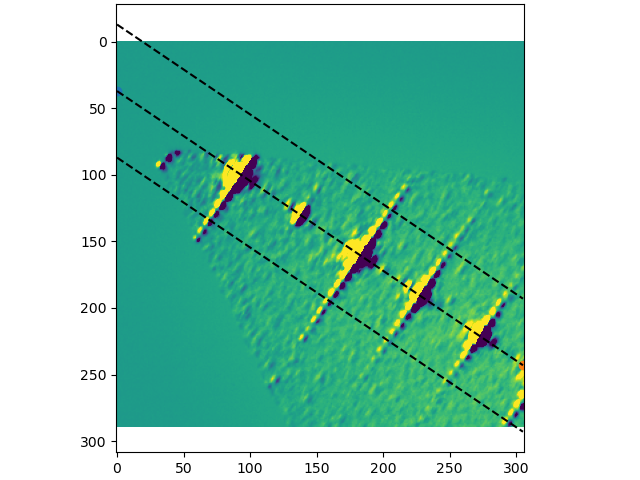

In [17]:
fig,ax=plt.subplots()

energy=455
m_bias=10
im1=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values
m_bias=0
im0=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values

ax.imshow(im1-im0  , vmin=-10, vmax=10)
ax.scatter(P1[1], P1[0])
ax.scatter(P2[1], P2[0])
ax.plot([P1[1], P2[1]],[P1[0]-50, P2[0]-50], ls="--", c="k")
ax.plot([P1[1], P2[1]],[P1[0]+50, P2[0]+50], ls="--", c="k")

ax.plot([P1[1], P2[1]],[P1[0], P2[0]], ls="--", c="k")

# dirty look

interactive(children=(FloatRangeSlider(value=(-1214.2234819335936, 1035.6136364746774), description='contrast'…

(<Figure size 700x700 with 1 Axes>, <Axes: >)

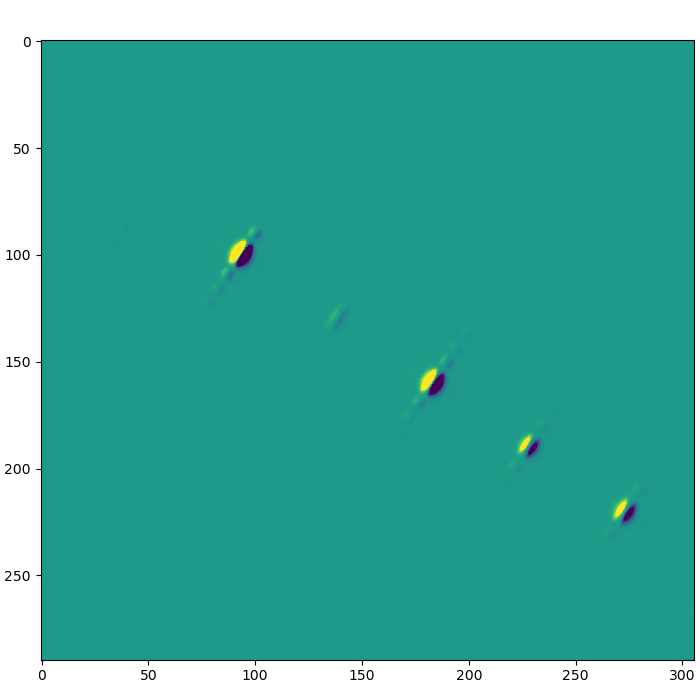

In [18]:
energy=455
m_bias=10
im1=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values
m_bias=0
im0=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values

cimshow(im1-im0, vmin=0,vmax=100)

In [ ]:
for energy in databin.energy.values:
    for m_bias in databin.energy.values[1:]:
        
        im=[0,0]
        im[0]=databin.sel(m_bias=0, method="nearest").sel(energy=energy, method="nearest")["images"].values
        im[1]=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values
    
    
        #SHIFT
        shift = cci.image_registration(
        im[0],
        im[1],
        method="dipy")
        im[1] = cci.shift_image(im[1], shift)
    
    
        
        #normalize
        # Get scaling factor and offset
        factor, offset = cci.dyn_factor(
            im[1][-20:,-100:],
            im[0][-20:,-100:] ,
            method="correlation",
            verbose=True,
            plot=True,
        )
        
        diff_c = im[1] / factor - im[0] - offset
        sum_c = im[1] / factor + im[0] - offset
    
    
        
        fig,ax=plt.subplots()
        ax.imshow((diff_c)  , vmin=-10, vmax=10)
        ax.scatter(P1[1], P1[0])
        ax.scatter(P2[1], P2[0])
        #ax.plot([P1[1], P2[1]],[P1[0]-50, P2[0]-50], ls="--", c="k")
        #ax.plot([P1[1], P2[1]],[P1[0]+50, P2[0]+50], ls="--", c="k")
        ax.plot([P1[1], P2[1]],[P1[0], P2[0]], ls="--", c="k")
        
        
        theta = np.arctan2(P1[1]- P2[1],P1[0]- P2[0])          # radians
        theta_deg = np.degrees(theta)       # degrees
        from scipy.ndimage import rotate
        diff2 = rotate(diff_c, angle=-theta_deg-90, reshape=False, order=1, mode="constant", cval=0.0)
        diff2=diff2[240-50:240+50]
        
        fig,ax=plt.subplots(4,1)
        ax[0].imshow((diff2)  , vmin=-10, vmax=10)
        linescan=line_scan((im[0][roi]), P1[1], P1[0], P2[1], P2[0], num=None)
        ax[1].plot(linescan)
        ax[2].plot(linescan)
        linescan=line_scan((im[1][roi]), P1[1], P1[0], P2[1], P2[0], num=None)
        ax[1].plot(linescan, ls="--")
        ax[2].plot(linescan, ls="--")
        mi,ma=np.percentile(linescan,(0,85))
        mi-=20
        #mi=-10
        ax[2].set_ylim(mi,ma)
        
        
        linescan=line_scan(((diff_c)[roi]), P1[1], P1[0], P2[1], P2[0], num=None)
        ax[3].plot(linescan, ls="-")
        ax[3].set_ylim(-5,5)
        #ax[0].set_xlabel("pixel")
        #ax[0].set_ylabel("pixel")
        #ax[1].set_xlabel("pixel")
        ax[3].set_xlabel("pixels")
        ax[1].set_ylabel("I (a.u.)")
        ax[2].set_ylabel("I (a.u.)")
        ax[3].set_ylabel("XMCD (a.u.)")
        
        
        fig.suptitle("imID = %s \n %0.2f V  -  %0.1f eV"%(im_ids, m_bias, energy))
    
    
        plt.savefig("/asap3/petra3/gpfs/p04/2026/data/11022228/processed/imID =%s_V=%0.2fV_E=%0.1feV.png"%(im_ids, m_bias, energy))

In [26]:
import numpy as np
from scipy.ndimage import zoom

def rescale_cubic(img: np.ndarray, scale, *, prefilter: bool = True, mode: str = "reflect", cval: float = 0.0) -> np.ndarray:
    """
    Rescale a 2D numpy array using cubic (3rd-order) interpolation.

    Parameters
    ----------
    img : np.ndarray
        2D array (H, W).
    scale : float or tuple[float, float]
        If float: uniform scale factor for both axes.
        If tuple: (scale_y, scale_x).
    prefilter : bool
        SciPy spline prefilter (keep True for best quality).
    mode : str
        How to handle borders (e.g. "reflect", "nearest", "constant", "mirror", "wrap").
    cval : float
        Used only if mode="constant".

    Returns
    -------
    np.ndarray
        Rescaled array.
    """
    if img.ndim != 2:
        raise ValueError(f"img must be 2D, got shape {img.shape}")

    if isinstance(scale, (int, float, np.floating)):
        zoom_factors = (float(scale), float(scale))
    else:
        if len(scale) != 2:
            raise ValueError("scale must be a float or a (scale_y, scale_x) tuple")
        zoom_factors = (float(scale[0]), float(scale[1]))

    return zoom(img, zoom=zoom_factors, order=3, mode=mode, cval=cval, prefilter=prefilter)


import numpy as np
from scipy.ndimage import affine_transform

def zoom_keep_shape(img: np.ndarray, zoom_factor: float, order: int = 3,
                    mode: str = "reflect", cval: float = 0.0) -> np.ndarray:
    """
    Zoom a 2D array with cubic interpolation while keeping output shape unchanged.

    zoom_factor > 1  → zoom in
    zoom_factor < 1  → zoom out
    """

    if img.ndim != 2:
        raise ValueError("Input must be 2D")

    h, w = img.shape

    # Scaling matrix (inverse because affine_transform maps output -> input)
    matrix = np.array([[1/zoom_factor, 0],
                       [0, 1/zoom_factor]])

    # Center coordinates
    center = np.array([h/2, w/2])

    # Offset so scaling happens around the center
    offset = center - matrix @ center

    return affine_transform(
        img,
        matrix=matrix,
        offset=offset,
        output_shape=(h, w),
        order=order,     # 3 = cubic
        mode=mode,
        cval=cval
    )


454.9983233
Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
[6.4  8.52]
Linear Fit: 1.5301*x + -2.4103
Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
[0. 0.]
No shift required
Linear Fit: 0.0151*x + -4.6362
Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
[6.04 8.24]
Linear Fit: 1.6060*x + -7.1071
Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
[0. 0.]
No shift required
Linear Fit: 0.0134*x + -4.0478


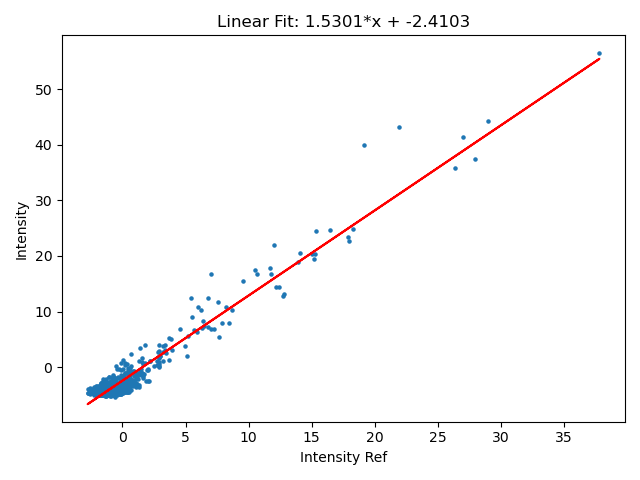

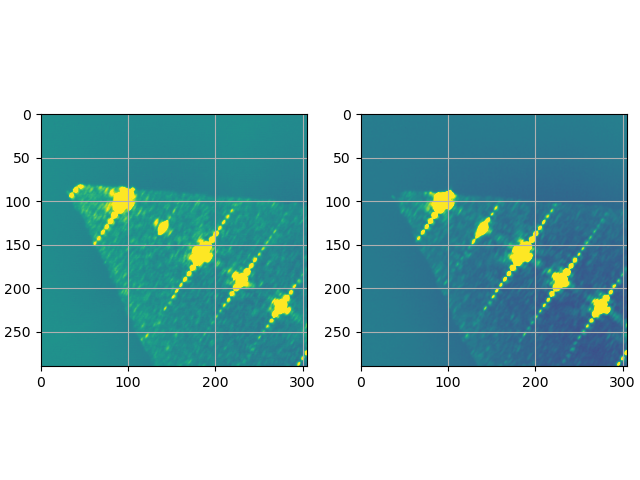

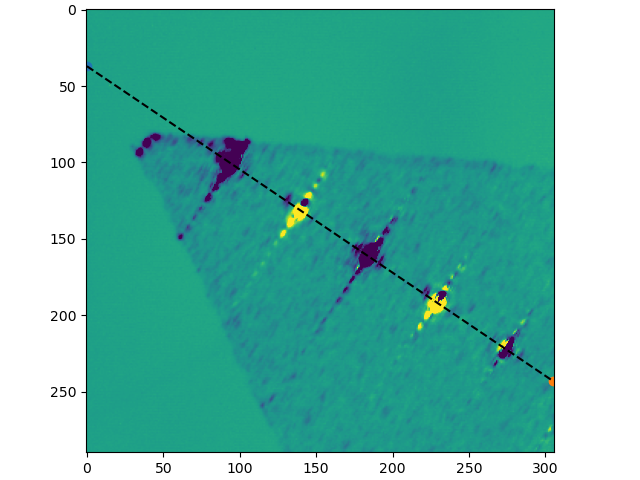

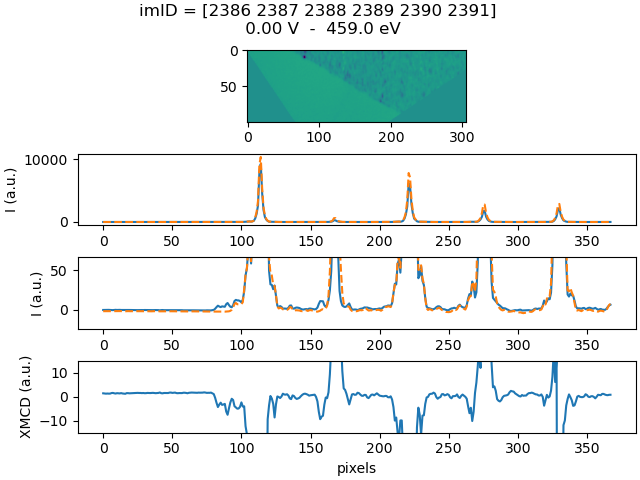

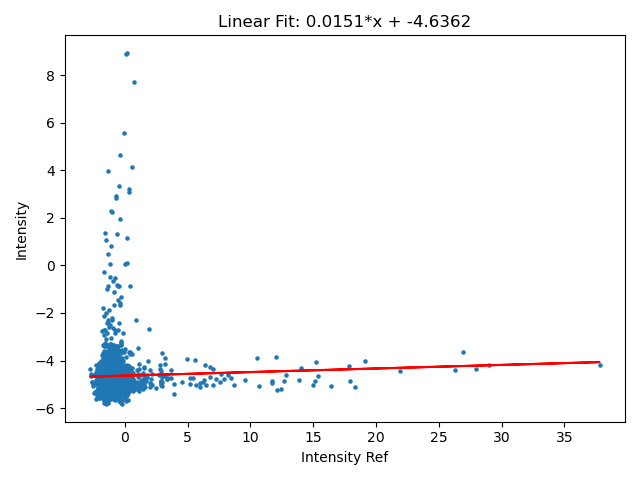

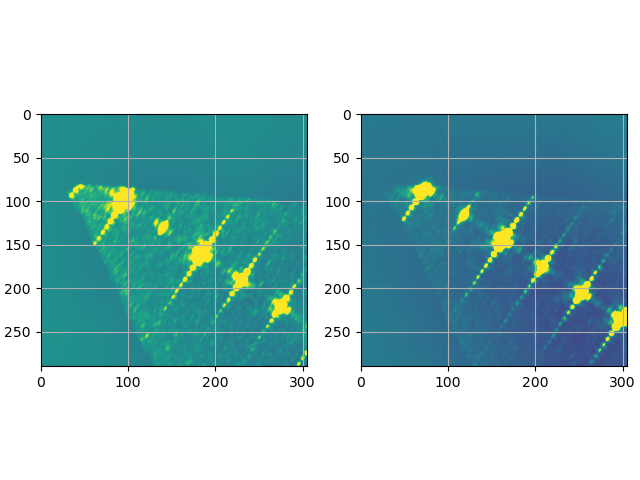

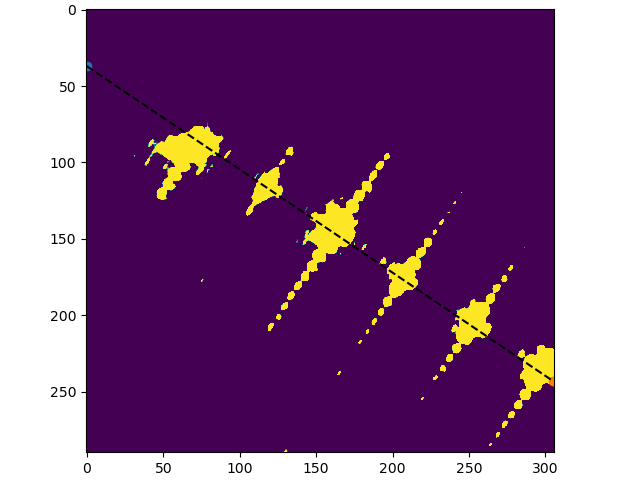

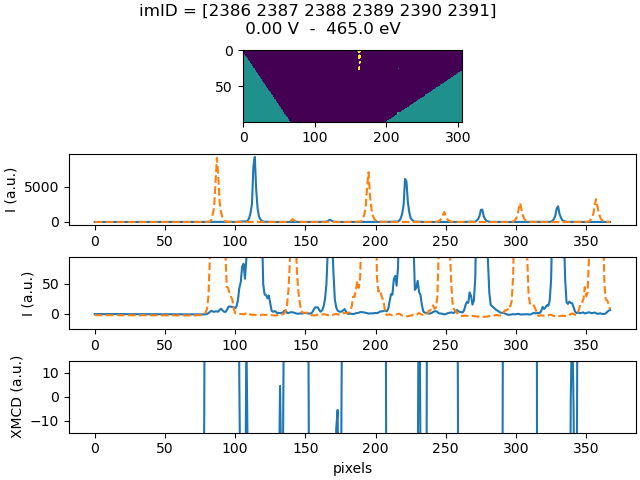

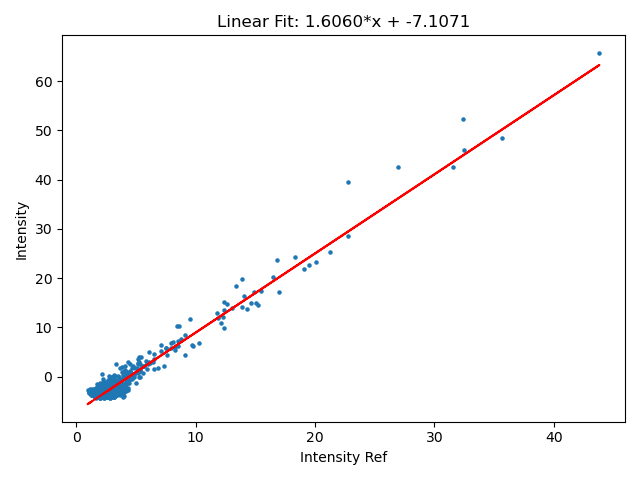

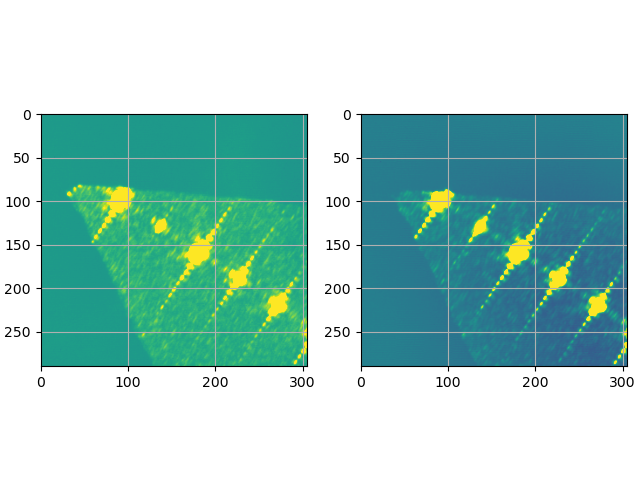

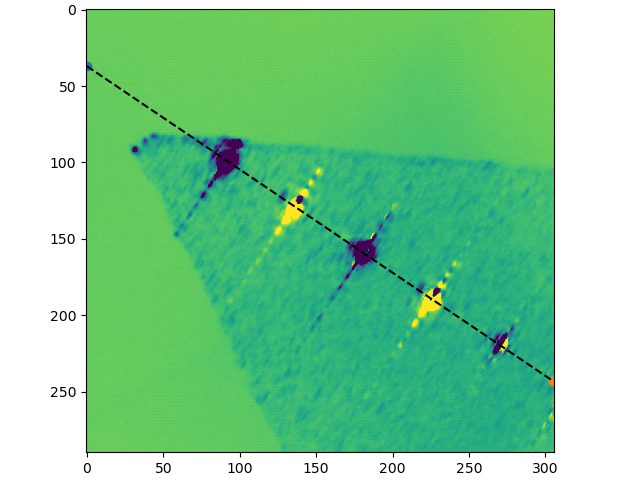

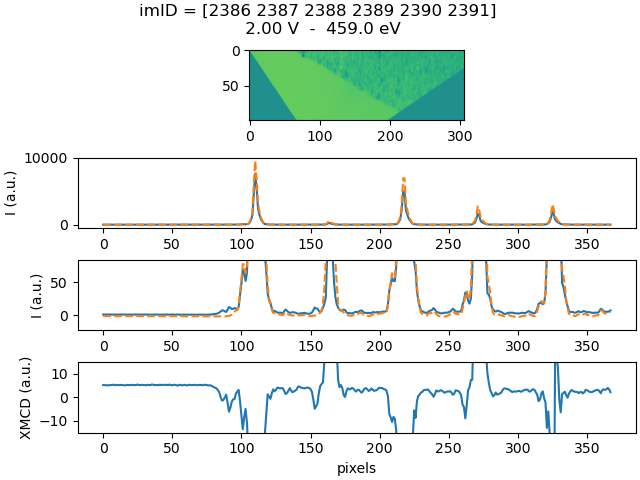

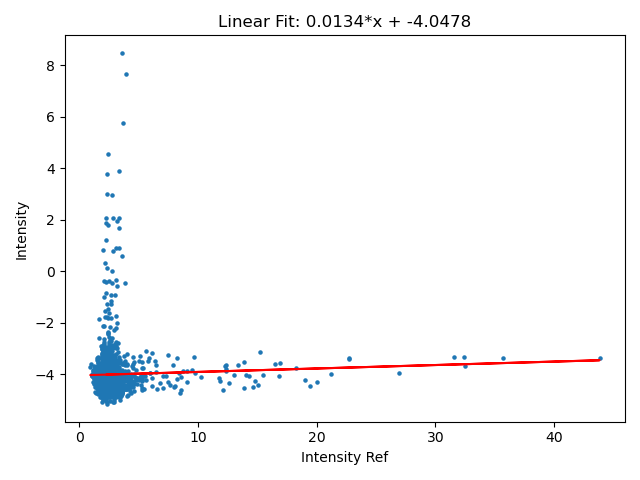

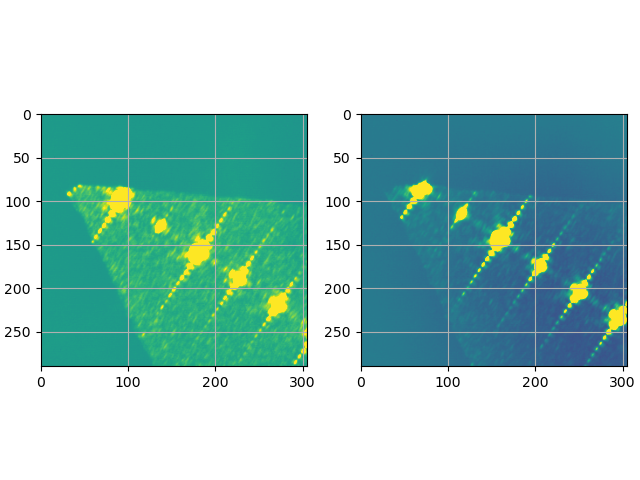

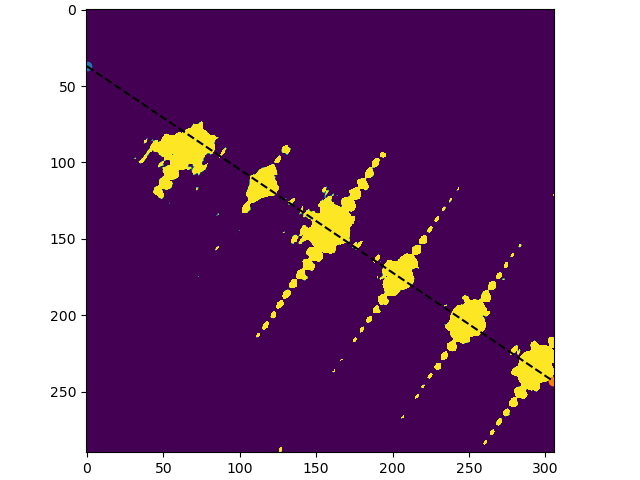

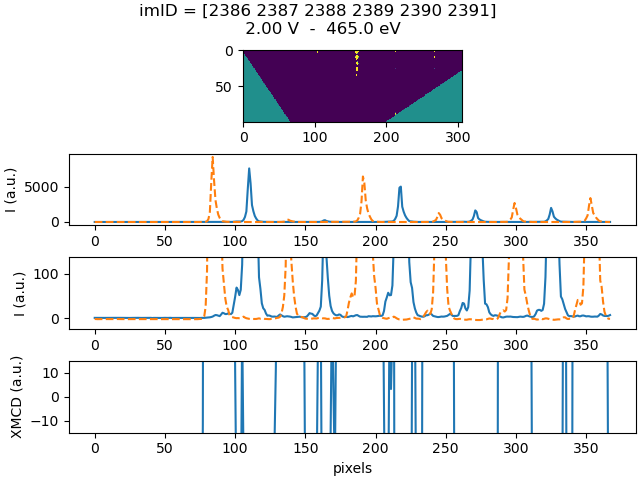

In [31]:
# ENERGY DICHROIC

zoomenergy=True
minenergy=np.amin(databin.energy.values)
print(minenergy)


for m_bias in databin.m_bias.values[:]:
    for energy in databin.energy.values[1:]:
    
        
        im=[0,0]
        im[0]=databin.sel(m_bias=m_bias, method="nearest").sel(energy=minenergy, method="nearest")["images"].values
        im[1]=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values

        #ZOOM
        if zoomenergy:
            scalefactor=energy/minenergy
            zoomed = zoom_keep_shape(im[1], scalefactor)
            im[1]=zoomed.copy()
    
        #SHIFT
        shift = cci.image_registration(
        im[0],
        im[1],
        method="dipy")
        print(shift)
        im[1] = cci.shift_image(im[1], shift)
    
    
        
        #normalize
        # Get scaling factor and offset
        factor, offset = cci.dyn_factor(
            im[1][-20:,-100:],
            im[0][-20:,-100:] ,
            method="correlation",
            verbose=True,
            plot=True,
        )
        
        diff_c = im[1] / factor - im[0] - offset
        sum_c = im[1] / factor + im[0] - offset
    
        
        fig,ax=plt.subplots(1,2)
        ax[0].imshow(im[0]  , vmin=-10, vmax=10)    
        ax[1].imshow(im[1]  , vmin=-10, vmax=10)   
        ax[0].grid()
        ax[1].grid()
        
        fig,ax=plt.subplots()
        ax.imshow((diff_c)  , vmin=-10, vmax=10)
        ax.scatter(P1[1], P1[0])
        ax.scatter(P2[1], P2[0])
        #ax.plot([P1[1], P2[1]],[P1[0]-50, P2[0]-50], ls="--", c="k")
        #ax.plot([P1[1], P2[1]],[P1[0]+50, P2[0]+50], ls="--", c="k")
        ax.plot([P1[1], P2[1]],[P1[0], P2[0]], ls="--", c="k")
        
        
        theta = np.arctan2(P1[1]- P2[1],P1[0]- P2[0])          # radians
        theta_deg = np.degrees(theta)       # degrees
        from scipy.ndimage import rotate
        diff2 = rotate(diff_c, angle=-theta_deg-90, reshape=False, order=1, mode="constant", cval=0.0)
        diff2=diff2[240-50:240+50]
        
        fig,ax=plt.subplots(4,1)
        ax[0].imshow((diff2)  , vmin=-10, vmax=10)
        linescan=line_scan((im[0][roi]), P1[1], P1[0], P2[1], P2[0], num=None)
        ax[1].plot(linescan)
        ax[2].plot(linescan)
        linescan=line_scan((im[1][roi]), P1[1], P1[0], P2[1], P2[0], num=None)
        ax[1].plot(linescan, ls="--")
        ax[2].plot(linescan, ls="--")
        mi,ma=np.percentile(linescan,(0,85))
        mi-=20
        #mi=-10
        ax[2].set_ylim(mi,ma)
        
        
        linescan=line_scan(((diff_c)[roi]), P1[1], P1[0], P2[1], P2[0], num=None)
        ax[3].plot(linescan, ls="-")
        ax[3].set_ylim(-15,15)
        #ax[0].set_xlabel("pixel")
        #ax[0].set_ylabel("pixel")
        #ax[1].set_xlabel("pixel")
        ax[3].set_xlabel("pixels")
        ax[1].set_ylabel("I (a.u.)")
        ax[2].set_ylabel("I (a.u.)")
        ax[3].set_ylabel("XMCD (a.u.)")
        
        
        fig.suptitle("imID = %s \n %0.2f V  -  %0.1f eV"%(im_ids, m_bias, energy))
    
    
        plt.savefig("/asap3/petra3/gpfs/p04/2026/data/11022228/processed/imID =%s_V=%0.2fV_E=%0.1feV.png"%(im_ids, m_bias, energy))